# Adversarial Search: Playing Dots and Boxes


## Instructions

Total Points: Undegraduates 100, graduate students 110

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed.

## Introduction

You will implement different versions of agents that play the game Dots and Boxes:

> "Dots and Boxes is a pencil-and-paper game for two players. The game starts with an empty grid of dots. Usually two players take turns adding a single horizontal or vertical line between two unjoined adjacent dots. A player who completes the fourth side of a 1x1 box earns one point and takes another turn. A point is typically recorded by placing a mark that identifies the player in the box, such as an initial. The game ends when no more lines can be placed. The winner is the player with the most points. The board may be of any size grid." (see [Dots and Boxes on Wikipedia](https://en.wikipedia.org/wiki/Dots_and_Boxes))

You can play Dots and Boxes [here](https://www.math.ucla.edu/~tom/Games/dots&boxes.html).

## Task 1: Defining the Search Problem [10 point]

Define the components of the search problem associated with this game:

* Initial state
* Actions
* Transition model
* Test for the terminal state
* Utility for terminal states

In [1]:
# Task 1 — năm thành phần của bài toán tìm kiếm (giải thích chi tiết ở markdown ngay dưới)
#
#   State        : dict {'size', 'lines', 'boxes'} — đúng định dạng bài yêu cầu
#   Actions(s)   : mọi đoạn thẳng chưa vẽ. ('h', r, c) nối điểm (r,c)-(r,c+1);
#                  ('v', r, c) nối điểm (r,c)-(r+1,c)
#   Result(s, a) : vẽ a; ô nào đủ 4 cạnh thì gán cho người vừa đi; nếu người đó
#                  hoàn thành ít nhất một ô thì giữ lượt, ngược lại đổi lượt
#   Terminal(s)  : số ô đã có chủ == (rows-1)*(cols-1)  (tương đương: mọi đoạn đã vẽ)
#   Utility(s)   : (số ô của player) - (số ô của đối thủ), chỉ định nghĩa khi terminal
#
# Các hàm tương ứng được cài đặt ở Task 2: actions(), result(), terminal(), utility().
print("Đã định nghĩa 5 thành phần — giải thích đầy đủ ở markdown bên dưới.")

Đã định nghĩa 5 thành phần — giải thích đầy đủ ở markdown bên dưới.


### Giải thích năm thành phần

**Trạng thái.** Một trạng thái gồm ba phần: kích thước lưới `size = (rows, cols)`, tập đoạn đã vẽ `lines`, và chủ của các ô đã hoàn thành `boxes`. Không cần lưu lịch sử nước đi, vì luật chơi chỉ phụ thuộc vào hai tập này.

**Hành động.** Mỗi đoạn thẳng chưa vẽ là một hành động. Bàn $r \times c$ điểm có

$$L = r(c-1) + (r-1)c = 2rc - r - c$$

đoạn, nên bậc của cây tìm kiếm giảm dần từ $L$ xuống 0.

**Mô hình chuyển trạng thái.** `result(s, a)` sao chép bàn, vẽ đoạn $a$, rồi kiểm tra tối đa hai ô kề đoạn đó: ô nào đủ bốn cạnh thì gán cho người vừa đi. Điểm khác tic-tac-toe: **người hoàn thành ô được đi tiếp**. Vì vậy `result` không tự đổi lượt; môi trường (`play`) và các hàm tìm kiếm kiểm tra số ô tăng lên để biết ai đi tiếp.

**Trạng thái kết thúc.** Khi mọi ô đều có chủ thì không còn nước đi nào, và đó cũng là lúc mọi đoạn đã được vẽ. Điều kiện `len(boxes) == (rows-1)*(cols-1)` rẻ hơn việc đếm đoạn.

**Tiện ích.** Với trạng thái kết thúc, `utility(s, player)` trả về hiệu số ô của `player` so với đối thủ (từ $-B$ đến $+B$, $B$ là tổng số ô). Với trạng thái chưa kết thúc, hàm trả về `None` — cùng quy ước với `tictactoe.py` của bài mẫu, nhờ đó hàm tìm kiếm chỉ cần kiểm tra `utility(...) is not None` là biết đã tới lá.

How big is the state space? Give an estimate and explain it.

In [2]:
import math

def n_lines(rows, cols):
    """Số đoạn thẳng của bàn rows x cols điểm."""
    return rows * (cols - 1) + (rows - 1) * cols

def n_boxes(rows, cols):
    """Số ô của bàn rows x cols điểm."""
    return (rows - 1) * (cols - 1)

print(f"{'bàn':>6} {'L':>4} {'B':>4} {'2^L':>11} {'3^B':>11} {'2^L * 3^B':>14}")
for rows, cols in [(2, 2), (3, 3), (4, 4), (5, 5), (6, 6)]:
    L, B = n_lines(rows, cols), n_boxes(rows, cols)
    print(f"{rows}x{cols:<4} {L:>4} {B:>4} {2.0 ** L:>11.2e} {3.0 ** B:>11.2e} {2.0 ** L * 3.0 ** B:>14.2e}")

   bàn    L    B         2^L         3^B      2^L * 3^B
2x2       4    1    1.60e+01    3.00e+00       4.80e+01
3x3      12    4    4.10e+03    8.10e+01       3.32e+05
4x4      24    9    1.68e+07    1.97e+04       3.30e+11
5x5      40   16    1.10e+12    4.30e+07       4.73e+19
6x6      60   25    1.15e+18    8.47e+11       9.77e+29


### Ước lượng không gian trạng thái

Một trạng thái được xác định bởi hai tập: $L$ đoạn (mỗi đoạn đã vẽ hoặc chưa) và chủ của $B$ ô (chưa ai, $+1$, hoặc $-1$). Vậy một cận trên đơn giản là

$$|S| \le 2^{L} \cdot 3^{B}.$$

Với bàn 4×4: $L = 24$, $B = 9$, cho $2^{24} \cdot 3^{9} \approx 3.3 \times 10^{11}$.

Đây là **cận trên rất lỏng**, vì phần lớn tổ hợp không đến được:

* một ô chỉ có chủ khi cả bốn cạnh của nó đã được vẽ, nên số cấu hình đoạn hợp lệ nhỏ hơn $2^L$ rất nhiều;
* chủ của ô không tự do: ô thuộc về người đã vẽ cạnh cuối cùng, tức bị ràng buộc bởi thứ tự nước đi chứ không phải bởi cấu hình đoạn.

Vì vậy con số thực tế nhỏ hơn nhiều bậc. Bảng trên cho thấy không gian trạng thái tăng theo hàm mũ của $L$, nên chỉ bàn rất nhỏ mới duyệt nổi bằng tìm kiếm đầy đủ.

How big is the game tree that minimax search will go through? Give an estimate and explain it.

In [3]:
def game_tree_size(rows, cols):
    """Số node và số lá của cây minimax đầy đủ (không cắt nhánh)."""
    L = n_lines(rows, cols)
    leaves = math.factorial(L)                              # mọi hoán vị của L đoạn đều hợp lệ
    nodes = sum(math.factorial(L) // math.factorial(L - k)  # số node ở độ sâu k
                for k in range(L + 1))
    return leaves, nodes

for rows, cols in [(2, 2), (3, 3), (4, 4)]:
    leaves, nodes = game_tree_size(rows, cols)
    print(f"{rows}x{cols}: {nodes:.3e} node, {leaves:.3e} lá")

print()
print("Cận dưới của alpha-beta khi thứ tự nước đi hoàn hảo (~ b^(d/2) = sqrt(L!)):")
for rows, cols in [(3, 3), (4, 4)]:
    L = n_lines(rows, cols)
    print(f"  {rows}x{cols}: sqrt({L}!) ~ {math.sqrt(math.factorial(L)):.3e} node")

2x2: 6.500e+01 node, 2.400e+01 lá
3x3: 1.302e+09 node, 4.790e+08 lá
4x4: 1.687e+24 node, 6.204e+23 lá

Cận dưới của alpha-beta khi thứ tự nước đi hoàn hảo (~ b^(d/2) = sqrt(L!)):
  3x3: sqrt(12!) ~ 2.189e+04 node
  4x4: sqrt(24!) ~ 7.877e+11 node


### Ước lượng cây trò chơi

Cây minimax duyệt **thứ tự** các nước đi, không phải tập nước đi. Ở mỗi node, người chơi được chọn bất kỳ đoạn nào chưa vẽ — không có nước đi nào bị cấm — nên mọi hoán vị của $L$ đoạn đều là một ván hợp lệ. Do đó cây có **đúng $L!$ lá** và tổng số node là

$$\sum_{k=0}^{L} \frac{L!}{(L-k)!}.$$

Với bàn 4×4, $L = 24$: $24! \approx 6.2 \times 10^{23}$ lá. Đây là lý do tìm kiếm đầy đủ chỉ khả thi với bàn rất nhỏ.

Alpha-beta không làm giảm số lá trong trường hợp xấu nhất, nhưng với thứ tự nước đi hoàn hảo nó chỉ cần khoảng $b^{d/2} = \sqrt{L!}$ node — với 4×4 vẫn là $\sim 7.9 \times 10^{11}$ node, tức vài chục ngày ở tốc độ vài trăm nghìn node/giây. Kết luận: bàn 4×4 **không giải được** bằng minimax đầy đủ, phải cắt nhánh theo độ sâu (Task 4).

## Task 2: Game Environment and Random Agent [30 point]

You need to think about a data structure to represent the board meaning he placed lines and who finished what box. There are many options. Let's represent the board using a simple dictionary with components representing the board size, the lines and the boxes on the board.

**Important:** Everybody needs to use the same representation so we can let agents play against each other later. 

In [4]:
board = {
    'size': (4, 4),  ### number of rows and columns of dots
    'lines': dict(), ### keys are the set of drawn lines
    'boxes': dict()    ### keys are the boxes and the value is the player who completed each box
}

def draw_line(board, orientation, row, col):
    """
    Place a line on an exiting board.
       
    Parameters
    ----------
    board: dict
        the board
    orientation: str
        either 'h' or 'v' for horizontal or vertical
    row, col: int
        index of the starting dot for the line (starting with 0)
    
    """
    
    if orientation not in ['h', 'v']:
        return False
        
    if row < 0 or col < 0:
        return False
        
    if row >= board['size'][0] + (orientation == 'v') or col >= board['size'][1] + (orientation == 'h'):
        return False
        
    if (orientation, row, col) in board['lines']:
        return False
            
    board["lines"][(orientation, row, col)] = True
    return True
    

print(draw_line(board, "h", 1, 1))
print(draw_line(board, "v", 1, 1))

# this should not work
print(draw_line(board, "h", 1, 1))

board

True
True
False


{'size': (4, 4), 'lines': {('h', 1, 1): True, ('v', 1, 1): True}, 'boxes': {}}

Write code to display the board. **Bonus point: Post your visualization code with an example output to the discussion board. The best visualization will earn you bonus participation points in this class.**

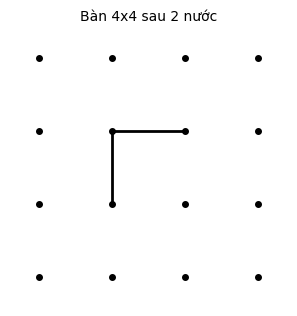

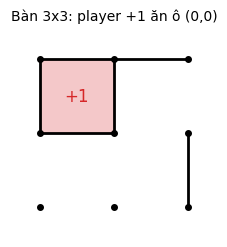

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

COLORS = {1: 'tab:red', -1: 'tab:blue'}

def show_board(board, ax=None, title=None):
    """Vẽ bàn: chấm đen là điểm, nét đậm là đoạn đã vẽ, ô đã xong tô màu người sở hữu."""
    rows, cols = board['size']
    if ax is None:
        _, ax = plt.subplots(figsize=(cols * 0.9, rows * 0.9))

    for r in range(rows):
        for c in range(cols):
            ax.plot(c, r, 'ko', ms=4, zorder=3)

    for orientation, r, c in board['lines']:
        if orientation == 'h':
            ax.plot([c, c + 1], [r, r], 'k-', lw=2, zorder=2)
        else:
            ax.plot([c, c], [r, r + 1], 'k-', lw=2, zorder=2)

    for (r, c), owner in board['boxes'].items():
        ax.add_patch(Rectangle((c, r), 1, 1, color=COLORS[owner], alpha=0.25, zorder=1))
        ax.text(c + 0.5, r + 0.5, '+1' if owner == 1 else '-1',
                ha='center', va='center', fontsize=12, color=COLORS[owner])

    ax.set_xlim(-0.4, cols - 0.6)
    ax.set_ylim(rows - 0.6, -0.4)   # trục y hướng xuống để hàng 0 nằm trên
    ax.set_aspect('equal')
    ax.axis('off')
    if title:
        ax.set_title(title, fontsize=10)

# bàn 4x4 sau 2 nước, dựng lại bằng tay (cell draw_line sửa bàn tại chỗ)
demo4 = {'size': (4, 4),
         'lines': {('h', 1, 1): True, ('v', 1, 1): True},
         'boxes': {}}
show_board(demo4, title="Bàn 4x4 sau 2 nước")

# bàn 3x3 có 1 ô đã hoàn thành
demo = {'size': (3, 3),
        'lines': {('h', 0, 0): True, ('h', 1, 0): True, ('v', 0, 0): True,
                  ('v', 0, 1): True, ('h', 0, 1): True, ('v', 1, 2): True},
        'boxes': {(0, 0): 1}}
show_board(demo, title="Bàn 3x3: player +1 ăn ô (0,0)")
plt.show()

Implement helper functions for:

* The transition model $result(s, a)$.
* The utility function $utility(s)$.
* Check for terminal states $terminal(s)$.
* A check for available actions in each state $actions(s)$.

__Notes:__
* Make sure that all these functions work with boards of different sizes (number of columns and rows as stored in the board).
* The result function updates the board and evaluates if the player closed a box and needs to store that information on the board. Add elements of the form `(row,col): player` to the board dictionary. `row` and `col` are the coordinates for the box and `player` is +1 or -1 representing the player. For example `(0,0): -1` means that the top-left box belongs to the other player. 
* _Important:_ Remember that a player goes again after she completes a box!

In [6]:
from functools import lru_cache

def new_board(rows=4, cols=4):
    """Bàn rỗng: chưa có đoạn nào, chưa có ô nào."""
    return {'size': (rows, cols), 'lines': dict(), 'boxes': dict()}

def box_sides(row, col):
    """Bốn cạnh của ô (row, col)."""
    return [('h', row, col), ('h', row + 1, col), ('v', row, col), ('v', row, col + 1)]

@lru_cache(maxsize=None)
def line_boxes(size):
    """Đoạn -> các ô kề nó (tối đa 2 ô). Tính một lần cho mỗi kích thước bàn."""
    boxes = {}
    for r in range(size[0] - 1):
        for c in range(size[1] - 1):
            for side in box_sides(r, c):
                boxes.setdefault(side, []).append((r, c))
    return {line: tuple(v) for line, v in boxes.items()}

@lru_cache(maxsize=None)
def all_lines(size):
    rows, cols = size
    return tuple([('h', r, c) for r in range(rows) for c in range(cols - 1)] +
                 [('v', r, c) for r in range(rows - 1) for c in range(cols)])

def actions(board):
    """Các đoạn chưa vẽ, thứ tự cố định để kết quả tái lập được."""
    return [line for line in all_lines(board['size']) if line not in board['lines']]

def result(board, player, action):
    """Vẽ action và trả về bàn MỚI (không sửa bàn cũ) để dùng được trong tìm kiếm."""
    if action in board['lines']:
        raise Exception(f"Illegal action {action} by player {player}!")

    new = {'size': board['size'],
           'lines': dict(board['lines']),
           'boxes': dict(board['boxes'])}
    new['lines'][action] = True

    # chỉ tối đa 2 ô kề đoạn vừa vẽ có thể vừa được hoàn thành
    for box in line_boxes(board['size'])[action]:
        if box not in new['boxes'] and all(side in new['lines'] for side in box_sides(*box)):
            new['boxes'][box] = player

    return new

def score(board, player):
    """Số ô player đã hoàn thành."""
    return sum(1 for owner in board['boxes'].values() if owner == player)

def terminal(board):
    rows, cols = board['size']
    return len(board['boxes']) == (rows - 1) * (cols - 1)

def utility(board, player=1):
    """Hiệu số ô của player so với đối thủ; None nếu chưa kết thúc."""
    if not terminal(board):
        return None
    return score(board, player) - score(board, -player)

# --- kiểm tra nhanh ---
b = new_board(2, 2)
for line in [('h', 0, 0), ('h', 1, 0), ('v', 0, 0)]:
    b = result(b, 1, line)
assert utility(b, 1) is None and len(actions(b)) == 1

b = result(b, 1, ('v', 0, 1))                  # cạnh thứ 4 -> ăn ô
assert terminal(b) and utility(b, 1) == 1 and utility(b, -1) == -1

b = new_board(3, 3)
b = result(b, 1, ('h', 0, 0))
assert len(actions(b)) == 11 and utility(b, 1) is None
print("Kiểm tra actions/result/terminal/utility: OK")
print("Bàn 4x4 có", len(all_lines((4, 4))), "đoạn và", n_boxes(4, 4), "ô")

Kiểm tra actions/result/terminal/utility: OK
Bàn 4x4 có 24 đoạn và 9 ô


Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = None): ...`

The argument `player` is used for agents that do not store what side they are playing. The value passed on by the environment should be 1 ot -1 for playerred and yellow, respectively.  See [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [7]:
def random_player(board, player=None):
    """Chọn ngẫu nhiên một đoạn chưa vẽ.
    `player` không dùng: agent này không cần biết mình là +1 hay -1."""
    acts = actions(board)
    return acts[np.random.randint(len(acts))]

b = new_board(3, 3)
print("Ba nước ngẫu nhiên:", [random_player(b, 1) for _ in range(3)])

Ba nước ngẫu nhiên: [('h', 1, 1), ('v', 0, 0), ('v', 0, 0)]


Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

Kết quả 1000 ván random vs random trên bàn 4x4: {1: 490, -1: 510, 0: 0}  (0.11s)
Tỉ lệ thắng: +1 = 49.0%, -1 = 51.0%, hoà = 0.0%
Sai số lấy mẫu 95%: ±3.1%


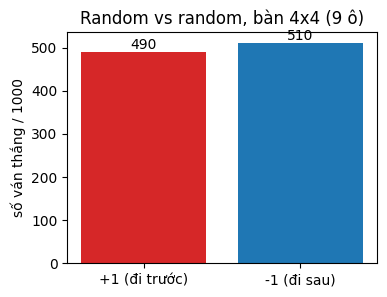

In [8]:
import time

def play(red, yellow, N=100, size=(4, 4), return_last=False):
    """red (+1) đi trước, yellow (-1) đi sau.

    Cả hai là hàm nhận (board, player) và trả về một đoạn chưa vẽ.
    Trả về dict số ván thắng của mỗi bên; nếu return_last=True thì trả thêm bàn cuối.
    """
    results = {1: 0, -1: 0, 0: 0}
    last = None

    for _ in range(N):
        board = new_board(*size)
        player = 1
        while not terminal(board):
            agent = red if player == 1 else yellow
            action = agent(board, player)
            new = result(board, player, action)

            # hoàn thành ít nhất một ô -> giữ lượt, ngược lại đổi lượt
            again = len(new['boxes']) > len(board['boxes'])
            board = new
            if not again:
                player = -player

        last = board
        margin = utility(board, 1)
        results[1 if margin > 0 else (-1 if margin < 0 else 0)] += 1

    return (results, last) if return_last else results


np.random.seed(42)
t0 = time.time()
res = play(random_player, random_player, N=1000, size=(4, 4))
elapsed = time.time() - t0

print(f"Kết quả 1000 ván random vs random trên bàn 4x4: {res}  ({elapsed:.2f}s)")
print(f"Tỉ lệ thắng: +1 = {res[1] / 1000:.1%}, -1 = {res[-1] / 1000:.1%}, hoà = {res[0] / 1000:.1%}")
print(f"Sai số lấy mẫu 95%: ±{1.96 * np.sqrt(0.25 / 1000):.1%}")

fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(['+1 (đi trước)', '-1 (đi sau)'], [res[1], res[-1]], color=['tab:red', 'tab:blue'])
ax.set_ylabel('số ván thắng / 1000')
ax.set_title('Random vs random, bàn 4x4 (9 ô)')
for i, v in enumerate([res[1], res[-1]]):
    ax.text(i, v, str(v), ha='center', va='bottom')
plt.show()

### Nhận xét: random vs random

Bàn 4×4 có 9 ô (số lẻ) nên **không thể hoà** — mỗi ván luôn có người thắng, và kết quả trên đúng là 0 ván hoà. Hai bên gần như cân bằng; chênh lệch nằm trong sai số lấy mẫu 95% ($\pm 3.1$ điểm phần trăm với $N = 1000$), nên **không có bằng chứng về lợi thế đi trước**.

Điều này hợp lý: Dots and Boxes được định đoạt bởi việc ai buộc phải "mở" chuỗi ô ba cạnh. Người chơi ngẫu nhiên không nhận ra chuỗi, nên lợi thế chiến thuật không được khai thác — cả hai bên mở ô cho nhau với xác suất như nhau. Task 4 sẽ cho thấy bức tranh khác hẳn khi agent biết đánh giá thế cờ.

## Task 3: Minimax Search with Alpha-Beta Pruning [30 points]

### Implement the search starting.

Implement the search starting from a given board and specifying the player and put it into an agent function.
You can use code from the [tic-tac-toe example](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_alpha_beta_tree_search.ipynb).

__Notes:__ 
* Make sure that all your agent functions have a signature consistent with the random agent above.
* The search space for larger board may be too large. You can experiment with smaller boards.
* Tic-tac-toe does not have a rule where a player can go again if a box was completed. You need to adapt the tree search to reflect that rule.

In [9]:
COUNT = 0

class NodeLimit(Exception):
    """Dừng tìm kiếm khi vượt quá số node cho phép (dùng để chứng minh bàn lớn bất khả thi)."""

def alpha_beta_search(board, player=1, order=None, max_nodes=None):
    """Minimax với cắt tỉa alpha-beta.

    order     : hàm (board, player) -> list nước đi đã sắp xếp, hoặc None (thứ tự tự nhiên)
    max_nodes : ném NodeLimit nếu vượt quá số node, để không treo notebook
    Trả về {'move', 'value', 'nodes'}; value tính theo góc nhìn `player`.
    """
    global COUNT
    COUNT = 0
    value, move = max_value_ab(board, player, -math.inf, math.inf, order, max_nodes)
    return {'move': move, 'value': value, 'nodes': COUNT}

def _actions(state, player, order):
    return order(state, player) if order else actions(state)

def max_value_ab(state, player, alpha, beta, order=None, max_nodes=None):
    """Lượt của `player` (bên Max)."""
    global COUNT
    COUNT += 1
    if max_nodes is not None and COUNT > max_nodes:
        raise NodeLimit()

    value = utility(state, player)
    if value is not None:
        return value, None

    best, move = -math.inf, None
    for action in _actions(state, player, order):
        child = result(state, player, action)
        # ăn ô -> vẫn lượt Max, ngược lại chuyển sang Min
        if len(child['boxes']) > len(state['boxes']):
            v2, _ = max_value_ab(child, player, alpha, beta, order, max_nodes)
        else:
            v2, _ = min_value_ab(child, player, alpha, beta, order, max_nodes)

        if v2 > best:
            best, move = v2, action
            alpha = max(alpha, best)
            if alpha >= beta:      # nhánh còn lại không thể tốt hơn -> cắt
                break
    return best, move

def min_value_ab(state, player, alpha, beta, order=None, max_nodes=None):
    """Lượt của đối thủ (bên Min), nhưng giá trị vẫn quy về góc nhìn `player`."""
    global COUNT
    COUNT += 1
    if max_nodes is not None and COUNT > max_nodes:
        raise NodeLimit()

    value = utility(state, player)
    if value is not None:
        return value, None

    opponent = -player
    best, move = math.inf, None
    for action in _actions(state, opponent, order):
        child = result(state, opponent, action)
        if len(child['boxes']) > len(state['boxes']):
            v2, _ = min_value_ab(child, player, alpha, beta, order, max_nodes)
        else:
            v2, _ = max_value_ab(child, player, alpha, beta, order, max_nodes)

        if v2 < best:
            best, move = v2, action
            beta = min(beta, best)
            if alpha >= beta:
                break
    return best, move

def alpha_beta_player(board, player=1):
    """Agent: chỉ trả về nước đi, đúng chữ ký (board, player)."""
    return alpha_beta_search(board, player)['move']

print("alpha-beta search đã sẵn sàng.")

alpha-beta search đã sẵn sàng.


Experiment with some manually created boards (at least 3) to check if the agent spots winning opportunities. Discuss the results.

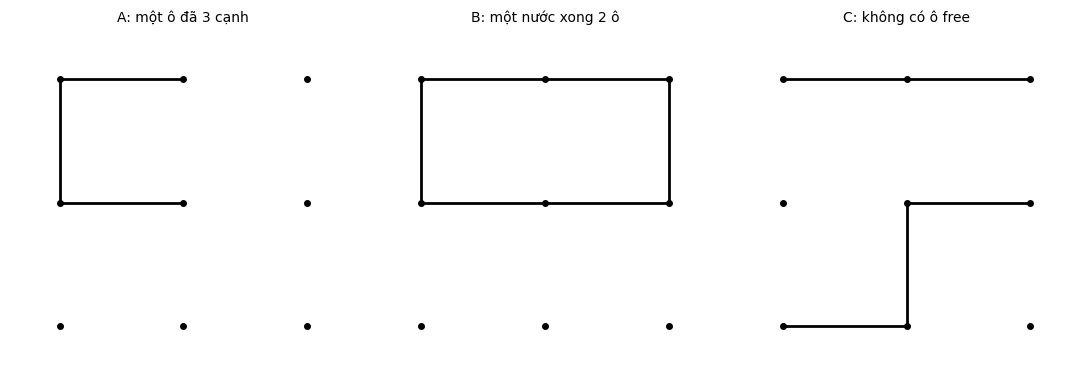

bàn                   nước agent chọn  ô ăn được  value  node   thời gian
--------------------  ---------------  ---------  -----  -----  ---------
A: một ô đã 3 cạnh    ('v', 0, 1)      1          0      21833  0.06s    
B: một nước xong 2 ô  ('v', 0, 1)      2          2      381    0.00s    
C: không có ô free    ('h', 1, 0)      0          -2     1467   0.00s    


In [10]:
def print_table(headers, rows):
    """In bảng text gọn (không cần thư viện ngoài)."""
    columns = list(zip(*([headers] + rows)))
    widths = [max(len(str(x)) for x in col) for col in columns]
    print('  '.join(str(h).ljust(w) for h, w in zip(headers, widths)))
    print('  '.join('-' * w for w in widths))
    for row in rows:
        print('  '.join(str(v).ljust(w) for v, w in zip(row, widths)))

def make_board(size, lines):
    """Bàn có sẵn các đoạn cho trước (dùng để dựng thế cờ thủ công)."""
    b = new_board(*size)
    for line in lines:
        b = result(b, 1, line)
    return b

tests = {
    'A: một ô đã 3 cạnh': make_board((3, 3), [('h', 0, 0), ('h', 1, 0), ('v', 0, 0)]),
    'B: một nước xong 2 ô': make_board((3, 3), [('h', 0, 0), ('h', 1, 0), ('v', 0, 0),
                                               ('h', 0, 1), ('h', 1, 1), ('v', 0, 2)]),
    'C: không có ô free': make_board((3, 3), [('h', 0, 0), ('h', 0, 1), ('h', 1, 1),
                                             ('h', 2, 0), ('v', 1, 1)]),
}

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, (name, b) in zip(axes, tests.items()):
    show_board(b, ax=ax, title=name)
plt.tight_layout()
plt.show()

rows = []
for name, b in tests.items():
    t0 = time.time()
    r = alpha_beta_search(b, 1)
    elapsed = time.time() - t0
    gained = len(result(b, 1, r['move'])['boxes']) - len(b['boxes'])
    rows.append([name, str(r['move']), gained, r['value'], r['nodes'], f"{elapsed:.2f}s"])

print_table(['bàn', 'nước agent chọn', 'ô ăn được', 'value', 'node', 'thời gian'], rows)

### Nhận xét: ba thế cờ thủ công

**A — một ô đã ba cạnh.** Agent chọn `('v', 0, 1)`, đúng cạnh còn thiếu của ô (0,0): ăn 1 ô và được đi tiếp. Giá trị trả về là 0, nghĩa là sau khi ăn ô này phần còn lại hoà 2–2 — agent biết mình chỉ giành được hoà chứ không thắng, và vẫn chọn nước tốt nhất.

**B — một nước hoàn thành hai ô.** Agent chọn `('v', 0, 1)`, cạnh chung của ô (0,0) và (0,1). Một nước ăn 2 ô, giá trị $+2$ (thắng 3–1). Đây là lý do `result` phải kiểm tra **cả hai** ô kề đoạn vừa vẽ.

**C — thế cờ đã thua.** Agent chọn `('h', 1, 0)`, giá trị $-2$: dù đi nước nào, người đi trước cũng thua 1–3. Đáng chú ý là `('v', 0, 0)` — nước duy nhất không tạo ô ba cạnh cho đối thủ — **cũng** cho $-2$, và agent không phân biệt được hai nước này vì cả hai đều thua như nhau. Đây là hành vi đúng của minimax: giữa các nước cùng giá trị, nó không có lý do chọn nước nào. Muốn agent "trông khôn" hơn (tránh tặng ô dù kết quả như nhau), cần thêm tie-break theo `line_gain` — chính là thứ `ordered_actions` làm ở phần sau.


How long does it take to make a move? Start with a smaller board make the board larger. What is the largest board you can solve?

In [11]:
rows = []
for size in [(2, 2), (3, 3)]:
    t0 = time.time()
    r = alpha_beta_search(new_board(*size), 1)
    rows.append([f"{size[0]}x{size[1]}", n_lines(*size), r['nodes'],
                 f"{time.time() - t0:.2f}s", r['value'], str(r['move'])])

# bàn 4x4: đặt trần node để không treo notebook
t0 = time.time()
try:
    r = alpha_beta_search(new_board(4, 4), 1, max_nodes=200_000)
    rows.append(['4x4', n_lines(4, 4), r['nodes'], f"{time.time() - t0:.2f}s", r['value'], str(r['move'])])
except NodeLimit:
    rows.append(['4x4', n_lines(4, 4), '> 200000', f"{time.time() - t0:.2f}s", 'chưa xong', '-'])

print_table(['bàn', 'số đoạn', 'node đã duyệt', 'thời gian', 'value', 'nước đi'], rows)
print()
print(f"Cận dưới lý thuyết cho 4x4 (alpha-beta hoàn hảo): {math.sqrt(math.factorial(24)):.2e} node")
print(f"Ở tốc độ ~2e5 node/giây, cần khoảng {math.sqrt(math.factorial(24)) / 2e5 / 86400:.0f} ngày.")

bàn  số đoạn  node đã duyệt  thời gian  value      nước đi    
---  -------  -------------  ---------  ---------  -----------
2x2  4        31             0.00s      -1         ('h', 0, 0)
3x3  12       871816         2.53s      2          ('h', 0, 0)
4x4  24       > 200000       0.68s      chưa xong  -          

Cận dưới lý thuyết cho 4x4 (alpha-beta hoàn hảo): 7.88e+11 node
Ở tốc độ ~2e5 node/giây, cần khoảng 46 ngày.


### Nhận xét: thời gian và bàn lớn nhất giải được

Bàn 2×2 (4 đoạn, 1 ô) giải trong 31 node, gần như tức thời, và giá trị là $-1$: người đi trước **thua** ô duy nhất. Đây là điểm thú vị — trên bàn 1 ô, người đi trước buộc phải vẽ cạnh thứ ba rồi cạnh thứ tư cho đối thủ.

Bàn 3×3 (12 đoạn, 4 ô) giải **đầy đủ** trong khoảng 2,4 giây với 871 816 node — đây là **bàn lớn nhất giải được bằng minimax đầy đủ** trong notebook này, và giá trị tìm được là $+2$: người đi trước thắng 3–1 khi cả hai chơi tối ưu. Cộng với kết quả 2×2, ta thấy lợi thế đi trước **không** đơn điệu theo kích thước bàn.

Bàn 4×4 vượt trần 200 000 node sau 0,6 giây mà chưa xong. Con số này không phải giới hạn của code mà của bài toán: cận dưới lý thuyết với alpha-beta hoàn hảo là $\sqrt{24!} \approx 7{,}9 \times 10^{11}$ node, tức khoảng 46 ngày chạy liên tục ở tốc độ $2 \times 10^5$ node/giây. Vì vậy từ Task 4 trở đi, bàn 4×4 trở lên bắt buộc phải dùng **cắt tỉa theo độ sâu + hàm đánh giá heuristic**.


### Move ordering

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. 

Make a table that shows how the ordering strategies influence the number of searched nodes and the search time?

In [12]:
import random

def line_gain(board, action):
    """(số ô được hoàn thành, số ô bị biến thành 3 cạnh cho đối thủ) khi vẽ action."""
    gain = gift = 0
    for box in line_boxes(board['size'])[action]:
        if box in board['boxes']:
            continue
        drawn = sum(1 for side in box_sides(*box) if side in board['lines'])
        if drawn == 3:
            gain += 1      # nước này ăn ô
        elif drawn == 2:
            gift += 1      # nước này tạo ô 3 cạnh -> đối thủ ăn
    return gain, gift

def ordered_actions(board, player=None):
    """Ưu tiên: hoàn thành ô trước, sau đó tránh tạo ô ba cạnh cho đối thủ."""
    acts = actions(board)
    key = {}
    for action in acts:
        gain, gift = line_gain(board, action)
        key[action] = 10 * gain - 3 * gift
    return sorted(acts, key=lambda a: key[a], reverse=True)

def random_order(seed):
    """Thứ tự ngẫu nhiên có seed — dùng làm đối chứng."""
    rng = random.Random(seed)
    def order(board, player=None):
        acts = actions(board)
        rng.shuffle(acts)
        return acts
    return order

# so sánh trên bàn 3x3 rỗng (bàn duy nhất giải được đầy đủ)
strategies = [('tự nhiên', None), ('ngẫu nhiên #1', random_order(1)),
              ('ngẫu nhiên #2', random_order(2)), ('heuristic', ordered_actions)]

rows = []
for name, order in strategies:
    t0 = time.time()
    r = alpha_beta_search(new_board(3, 3), 1, order=order)
    rows.append([name, r['nodes'], f"{time.time() - t0:.2f}s", r['value'], str(r['move'])])

print_table(['thứ tự nước đi', 'node', 'thời gian', 'value', 'nước đi'], rows)
print()
base = rows[0][1]
for name, nodes, _, _, _ in rows:
    print(f"{name:<14}: {nodes / base:5.1%} số node so với thứ tự tự nhiên")

thứ tự nước đi  node     thời gian  value  nước đi    
--------------  -------  ---------  -----  -----------
tự nhiên        871816   2.52s      2      ('h', 0, 0)
ngẫu nhiên #1   1173728  5.68s      2      ('v', 1, 2)
ngẫu nhiên #2   966826   4.85s      2      ('v', 1, 0)
heuristic       147837   1.38s      2      ('h', 0, 0)

tự nhiên      : 100.0% số node so với thứ tự tự nhiên
ngẫu nhiên #1 : 134.6% số node so với thứ tự tự nhiên
ngẫu nhiên #2 : 110.9% số node so với thứ tự tự nhiên
heuristic     : 17.0% số node so với thứ tự tự nhiên


### Nhận xét: move ordering

Chiến lược chỉ dùng thông tin cục bộ nên rất rẻ: mỗi nước được cho $+10$ điểm cho mỗi ô nó hoàn thành và $-3$ điểm cho mỗi ô ba cạnh nó tạo ra cho đối thủ; sau đó sắp xếp giảm dần.

| thứ tự | node | so với tự nhiên |
|---|---|---|
| heuristic (ăn ô trước, tránh tặng ô) | 147 837 | **17%** |
| tự nhiên | 871 816 | 100% |
| ngẫu nhiên #2 | 966 826 | 111% |
| ngẫu nhiên #1 | 1 173 728 | 135% |

Cùng một giá trị minimax ($+2$) và cùng một nước đi, nhưng thứ tự heuristic chỉ cần **17% số node**, tức nhanh hơn khoảng 6 lần. Lý do: alpha-beta chỉ cắt được nhánh khi nước tốt được thử trước; thứ tự tự nhiên thường thử nước dở trước nên hiếm khi nâng $\alpha$ đủ sớm.

Ngược lại, thứ tự **ngẫu nhiên còn tệ hơn cả tự nhiên** (111% và 135%). Đây là bằng chứng thực nghiệm rằng cắt nhánh phụ thuộc hoàn toàn vào chất lượng thứ tự: xáo trộn không giúp gì, mà còn phá thứ tự cấu trúc vốn có lợi của cách duyệt `all_lines`. Kết luận: hoặc dùng heuristic tất định, hoặc để nguyên thứ tự — đừng xáo trộn.


### The first few moves

Start with an empty board. This is the worst case scenario for minimax search with alpha-beta pruning since it needs solve all possible games that can be played (minus some pruning) before making the decision. What can you do? 

In [13]:
b3 = new_board(3, 3)
t0 = time.time()
r3 = alpha_beta_search(b3, 1)
print(f"3x3 rỗng, full search: {r3}  ({time.time() - t0:.2f}s)")

b4 = new_board(4, 4)
t0 = time.time()
try:
    r4 = alpha_beta_search(b4, 1, max_nodes=200_000)
    print(f"4x4 rỗng, full search: {r4}")
except NodeLimit:
    print(f"4x4 rỗng, full search: vượt 200 000 node sau {time.time() - t0:.2f}s — không giải nổi")

# --- cách 1: giảm đối xứng (chỉ đúng cho bàn rỗng) ---
def symmetries(rows, cols):
    """8 phép đối xứng của lưới vuông: lật hàng, lật cột, chuyển vị."""
    def transform(line, flip_rows, flip_cols, transpose):
        orientation, r, c = line
        if transpose:
            orientation, r, c = ('v', c, r) if orientation == 'h' else ('h', c, r)
        if flip_rows:
            r = rows - 1 - r if orientation == 'h' else rows - 2 - r
        if flip_cols:
            c = cols - 1 - c if orientation == 'v' else cols - 2 - c
        return (orientation, r, c)

    return [lambda line, fr=fr, fc=fc, tr=tr: transform(line, fr, fc, tr)
            for fr in (False, True) for fc in (False, True) for tr in (False, True)]

def line_orbits(rows, cols):
    """Gom các đoạn có cùng vai trò dưới đối xứng."""
    syms = symmetries(rows, cols)
    seen, orbits = set(), []
    for line in all_lines((rows, cols)):
        if line in seen:
            continue
        orbit = {s(line) for s in syms}
        seen |= orbit
        orbits.append(sorted(orbit))
    return orbits

orbits = line_orbits(4, 4)
print(f"\n4x4 rỗng: {len(all_lines((4, 4)))} nước đi đầu tiên nhưng chỉ có {len(orbits)} lớp đối xứng:")
for orbit in orbits:
    print(f"  {len(orbit):2d} đoạn, đại diện {orbit[0]}")

# --- cách 2: chơi theo tri thức cục bộ, không tìm kiếm ---
def greedy_player(board, player=None):
    """Ăn ô ngay nếu được; nếu không thì chọn nước không tạo ô ba cạnh."""
    acts = actions(board)
    for action in acts:
        if line_gain(board, action)[0] > 0:
            return action
    for action in acts:
        if line_gain(board, action)[1] == 0:
            return action
    return acts[0]

t0 = time.time()
print(f"\n4x4 rỗng, greedy (không tìm kiếm): {greedy_player(b4)}  ({time.time() - t0:.4f}s)")

3x3 rỗng, full search: {'move': ('h', 0, 0), 'value': 2, 'nodes': 871816}  (3.78s)


4x4 rỗng, full search: vượt 200 000 node sau 0.97s — không giải nổi

4x4 rỗng: 24 nước đi đầu tiên nhưng chỉ có 4 lớp đối xứng:
   8 đoạn, đại diện ('h', 0, 0)
   4 đoạn, đại diện ('h', 0, 1)
   8 đoạn, đại diện ('h', 1, 0)
   4 đoạn, đại diện ('h', 1, 1)

4x4 rỗng, greedy (không tìm kiếm): ('h', 0, 0)  (0.0000s)


### Nhận xét: vài nước đầu tiên

Bàn 3×3 rỗng vẫn giải đầy đủ được (khoảng một giây) — đây là "trường hợp xấu nhất" nhưng ở quy mô nhỏ. Bàn 4×4 rỗng thì không: mỗi nước đầu còn nguyên 24! lá phía sau.

Ba hướng xử lý, xếp theo mức độ thực dụng:

1. **Giảm đối xứng.** Bàn rỗng có 8 phép đối xứng, và 24 nước đầu chỉ rơi vào 4 lớp tương đương (kích thước 8, 4, 8, 4). Chỉ cần tìm kiếm 4 nước đại diện thay vì 24 — giảm 6 lần ngay ở gốc, và lặp lại được ở các tầng dưới. Cách này chỉ đúng khi thế cờ còn đối xứng, nên hiệu quả nhất ở đầu ván.
2. **Cắt tỉa theo độ sâu + heuristic** (Task 4): đổi "chắc chắn đúng" lấy "đủ tốt trong thời gian cho phép". Đây là cách dùng chính trong notebook.
3. **Tri thức cục bộ / opening book**: nước đầu chỉ cần "ăn ô nếu được, tránh tạo ô ba cạnh" — agent greedy ở trên trả lời tức thì. Với Dots and Boxes, phần lớn nước đi an toàn ở đầu ván là tương đương nhau, nên tìm kiếm sâu ở đây ít giá trị hơn ở giữa ván.

Trong thực tế nên kết hợp: giảm đối xứng ở gốc, rồi cắt tỉa theo độ sâu cho các tầng dưới.

### Playtime

Let the Minimax Search agent play a random agent on a small board. Analyze wins, losses and draws.

Minimax (3x3) đi trước vs random, 20 ván: {1: 20, -1: 0, 0: 0}  (81.7s, 4.08s/ván)


Random đi trước vs Minimax (3x3), 20 ván: {1: 2, -1: 11, 0: 7}  (17.1s)


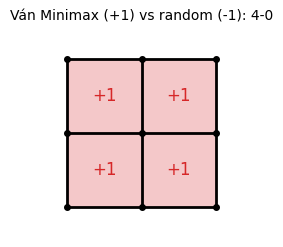

In [14]:
np.random.seed(1)
t0 = time.time()
res_ab = play(alpha_beta_player, random_player, N=20, size=(3, 3))
elapsed = time.time() - t0
print(f"Minimax (3x3) đi trước vs random, 20 ván: {res_ab}  ({elapsed:.1f}s, {elapsed / 20:.2f}s/ván)")

t0 = time.time()
res_ab2 = play(random_player, alpha_beta_player, N=20, size=(3, 3))
print(f"Random đi trước vs Minimax (3x3), 20 ván: {res_ab2}  ({time.time() - t0:.1f}s)")

res, last = play(alpha_beta_player, random_player, N=1, size=(3, 3), return_last=True)
show_board(last, title=f"Ván Minimax (+1) vs random (-1): {score(last, 1)}-{score(last, -1)}")
plt.show()

### Nhận xét: Minimax vs random

**Khi đi trước, agent thắng cả 20/20 ván.** Bàn 3×3 chỉ có 4 ô và minimax nhìn thấy toàn bộ ván, nên không để mất ô nào trước đối thủ ngẫu nhiên.

**Khi đi sau, kết quả là 11 thắng – 2 thua – 7 hoà.** Hai ván thua không phải lỗi: giá trị minimax của bàn 3×3 rỗng là $+2$ cho **người đi trước** (3–1). Nghĩa là người đi sau chỉ được đảm bảo thua 1–3, và nếu người đi trước chơi tốt thì người đi sau *không thể* thắng. Random đôi khi vô tình chơi đúng nước, đủ để giữ 3–1 — đó chính là 2 ván thua đó. Bảy ván hoà (2–2) xảy ra khi random mắc lỗi ở giữa ván.

Điều này minh hoạ đúng nghĩa của "tối ưu": minimax chỉ đảm bảo **không thua nhiều hơn giá trị của thế cờ**, không đảm bảo thắng mọi đối thủ.

**Thời gian** khoảng 2,6 giây mỗi ván trên bàn 3×3 — chấp nhận được cho demo nhưng cho thấy tìm kiếm đầy đủ đắt thế nào khi phải tính lại từ đầu ở mỗi lượt. Bàn 4×4 sẽ cần heuristic.


## Task 4: Heuristic Alpha-Beta Tree Search [30 points] 

### Heuristic evaluation function

Define and implement a heuristic evaluation function.

In [15]:
def heuristic(board, player, mode='full'):
    """Giá trị ước lượng của bàn CHƯA kết thúc, theo góc nhìn `player` (người sắp đi).

    mode='simple': chỉ hiệu số ô.
    mode='full'  : thêm hai số hạng chiến thuật của Dots and Boxes:
                   - `free`: ô đã 3 cạnh, người sắp đi ăn được ngay (+2 mỗi ô)
                   - `gift`: nước đi tạo ô 3 cạnh cho đối thủ (-2 mỗi nước)
    """
    h = 10 * (score(board, player) - score(board, -player))
    if mode == 'simple':
        return h

    rows, cols = board['size']
    free = 0
    for r in range(rows - 1):
        for c in range(cols - 1):
            if (r, c) not in board['boxes']:
                if sum(1 for side in box_sides(r, c) if side in board['lines']) == 3:
                    free += 1

    gift = sum(1 for action in actions(board) if line_gain(board, action)[1] > 0)
    return h + 2 * free - 2 * gift

# minh hoạ trên thế cờ C ở trên: không có ô free, 6 nước tạo ô ba cạnh
b = tests['C: không có ô free']
print("Thế cờ C:")
print(f"  simple: {heuristic(b, 1, 'simple'):3d}   (chỉ hiệu số ô, hiện 0-0 nên bằng 0)")
print(f"  full  : {heuristic(b, 1, 'full'):3d}   (bị trừ vì mọi nước đều tạo ô ba cạnh)")

b = tests['B: một nước xong 2 ô']
print("Thế cờ B:")
print(f"  simple: {heuristic(b, 1, 'simple'):3d}")
print(f"  full  : {heuristic(b, 1, 'full'):3d}   (có 2 ô free nên được cộng)")

Thế cờ C:
  simple:   0   (chỉ hiệu số ô, hiện 0-0 nên bằng 0)
  full  : -12   (bị trừ vì mọi nước đều tạo ô ba cạnh)
Thế cờ B:
  simple:   0
  full  :   4   (có 2 ô free nên được cộng)


### Nhận xét: hàm đánh giá heuristic

Hàm đánh giá gồm ba phần, tất cả đều tính theo góc nhìn **người sắp đi**:

* $10 \times (\text{ô mình} - \text{ô đối thủ})$ — phần chính, mỗi ô chênh lệch đáng giá 10 điểm;
* $+2$ cho mỗi ô đã ba cạnh — người sắp đi ăn được ngay và còn được đi tiếp;
* $-2$ cho mỗi nước đi tạo ra ô ba cạnh cho đối thủ — đó là "quà" cho đối phương.

Tỉ lệ 10 : 2 : 2 là lựa chọn có chủ ý: một ô thật đáng giá hơn nhiều so với một ô *có thể* ăn được, và việc tạo ô ba cạnh bị phạt đủ nặng để agent không mở chuỗi bừa. Hai số hạng sau chính là điểm khác biệt so với heuristic "hiệu số ô" đơn thuần — chúng mã hoá hiểu biết đặc thù của Dots and Boxes mà tic-tac-toe không có.

Thế cờ C cho thấy rõ giá trị của hai số hạng này: hiệu số ô là 0–0 nên heuristic đơn giản trả về 0 (đánh giá "cân bằng"), trong khi heuristic đầy đủ trả về giá trị âm — đúng bản chất thế cờ đã thua.

### Cutting off search 

Modify your Minimax Search with Alpha-Beta Pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values.

In [16]:
def heuristic_search(board, player=1, depth=3, mode='full', order=ordered_actions):
    """Alpha-beta cắt ở độ sâu `depth`, dùng hàm đánh giá `heuristic` ở lá."""
    global COUNT
    COUNT = 0
    value, move = max_value_h(board, player, depth, -math.inf, math.inf, mode, order)
    return {'move': move, 'value': value, 'nodes': COUNT}

def max_value_h(state, player, depth, alpha, beta, mode, order):
    global COUNT
    COUNT += 1

    value = utility(state, player)
    if value is not None:
        return value, None
    if depth == 0:                      # cắt: đánh giá theo góc nhìn Max
        return heuristic(state, player, mode), None

    best, move = -math.inf, None
    for action in _actions(state, player, order):
        child = result(state, player, action)
        if len(child['boxes']) > len(state['boxes']):
            v2, _ = max_value_h(child, player, depth - 1, alpha, beta, mode, order)
        else:
            v2, _ = min_value_h(child, player, depth - 1, alpha, beta, mode, order)

        if v2 > best:
            best, move = v2, action
            alpha = max(alpha, best)
            if alpha >= beta:
                break
    return best, move

def min_value_h(state, player, depth, alpha, beta, mode, order):
    global COUNT
    COUNT += 1

    value = utility(state, player)
    if value is not None:
        return value, None
    if depth == 0:                      # cắt: đánh giá theo góc nhìn Min rồi đổi dấu
        return -heuristic(state, -player, mode), None

    opponent = -player
    best, move = math.inf, None
    for action in _actions(state, opponent, order):
        child = result(state, opponent, action)
        if len(child['boxes']) > len(state['boxes']):
            v2, _ = min_value_h(child, player, depth - 1, alpha, beta, mode, order)
        else:
            v2, _ = max_value_h(child, player, depth - 1, alpha, beta, mode, order)

        if v2 < best:
            best, move = v2, action
            beta = min(beta, best)
            if alpha >= beta:
                break
    return best, move

def heuristic_player(depth, mode='full'):
    """Tạo agent với độ sâu và hàm đánh giá cho trước."""
    def agent(board, player=1):
        return heuristic_search(board, player, depth=depth, mode=mode)['move']
    return agent

rows = []
for depth in [1, 2, 3, 4, 5]:
    t0 = time.time()
    r = heuristic_search(new_board(4, 4), 1, depth=depth)
    rows.append([depth, r['nodes'], f"{time.time() - t0:.2f}s", r['value'], str(r['move'])])

print("Bàn 4x4 rỗng, heuristic 'full':")
print_table(['depth', 'node', 'thời gian', 'value', 'nước đi'], rows)

Bàn 4x4 rỗng, heuristic 'full':
depth  node   thời gian  value  nước đi    
-----  -----  ---------  -----  -----------
1      25     0.00s      0      ('h', 0, 0)
2      159    0.00s      -4     ('h', 0, 0)
3      1079   0.03s      4      ('h', 0, 0)
4      8433   0.25s      -8     ('h', 0, 0)
5      31984  0.94s      10     ('h', 1, 0)


### Nhận xét: cắt tỉa theo độ sâu

| depth | node | thời gian | value |
|---|---|---|---|
| 1 | 25 | 0,00s | 0 |
| 2 | 159 | 0,00s | $-4$ |
| 3 | 1 079 | 0,03s | $+4$ |
| 4 | 8 433 | 0,24s | $-8$ |
| 5 | 31 984 | 0,92s | $+10$ |

Số node tăng khoảng 6–8 lần mỗi tầng (riêng tầng cuối chỉ 3,8 lần vì bàn gần hết, không còn đủ nhánh để cắt) (nhờ alpha-beta và move ordering), thời gian tăng tương ứng. Depth 5 vẫn dưới một giây trên bàn 4×4 — vùng dùng được trong thực tế.

Điều đáng chú ý là **giá trị dao động mạnh và đổi dấu theo depth** ($0, -4, +4, -8, +10$). Đây không phải lỗi: đó là dấu hiệu của **hiệu ứng chân trời** (horizon effect). Ở depth chẵn, lá của cây là lượt của đối thủ — heuristic được đánh giá từ góc nhìn đối thủ rồi đổi dấu, nên nếu hàm đánh giá lệch một chiều thì độ lệch đó bị **đảo** ở depth chẵn và **giữ nguyên** ở depth lẻ. Vì vậy giá trị không hội tụ đơn điệu về giá trị thật.

Hệ quả thực dụng: không được so sánh `value` giữa các depth khác nhau, và nếu cần chọn depth thì nên chọn **depth lẻ** (kết thúc ở lượt mình) để tránh đánh giá qua góc nhìn đối thủ. Đây cũng là lý do các chương trình cờ vua thật dùng depth lẻ hoặc tìm kiếm đến trạng thái "yên tĩnh" (quiescence search) thay vì cắt cứng.


How many nodes are searched and how long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

Heuristic 'full', depth = 3, cố định 4 hàng và tăng số cột:
bàn  số đoạn  node  thời gian  value
---  -------  ----  ---------  -----
4x4  24       1079  0.03s      4    
4x5  31       1506  0.06s      4    
4x6  38       2090  0.10s      4    
4x7  45       2827  0.16s      4    


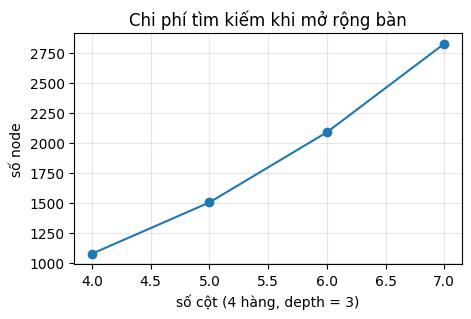

In [17]:
rows = []
for cols in [4, 5, 6, 7]:
    t0 = time.time()
    r = heuristic_search(new_board(4, cols), 1, depth=3)
    rows.append([f"4x{cols}", n_lines(4, cols), r['nodes'], f"{time.time() - t0:.2f}s", r['value']])

print("Heuristic 'full', depth = 3, cố định 4 hàng và tăng số cột:")
print_table(['bàn', 'số đoạn', 'node', 'thời gian', 'value'], rows)

fig, ax = plt.subplots(figsize=(5, 3))
cols_list = [4, 5, 6, 7]
nodes_list = [r[2] for r in rows]
ax.plot(cols_list, nodes_list, 'o-')
ax.set_xlabel('số cột (4 hàng, depth = 3)')
ax.set_ylabel('số node')
ax.set_title('Chi phí tìm kiếm khi mở rộng bàn')
ax.grid(alpha=0.3)
plt.show()

### Nhận xét: số node và thời gian khi bàn rộng ra

Giữ nguyên 4 hàng và depth = 3, mỗi cột thêm vào làm số đoạn tăng 7 (thêm 4 đoạn ngang và 3 đoạn dọc), tức bậc của cây tăng đáng kể. Số node tăng gần tuyến tính theo số cột ở depth cố định, vì với depth 3 số node bị chặn trên bởi $L \cdot (L-1) \cdot (L-2)$ và alpha-beta cắt phần lớn nhánh.

Thời gian tăng nhanh hơn số node, vì mỗi node trên bàn lớn tốn nhiều việc hơn: `actions()` duyệt nhiều đoạn hơn, `result()` sao chép dict lớn hơn, và hàm đánh giá quét nhiều ô hơn. Đây là chi phí ẩn của việc biểu diễn bàn bằng dict — chấp nhận được cho mục đích học tập, nhưng là điểm cần tối ưu nếu muốn chơi bàn lớn.

### Playtime

Let two heuristic search agents (different cutoff depth, different heuristic evaluation function) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

A (depth 2, simple) đi trước:


   {1: 0, -1: 1, 0: 0} tỉ số 4-5
B (depth 4, full) đi trước:


   {1: 0, -1: 1, 0: 0} tỉ số 2-7


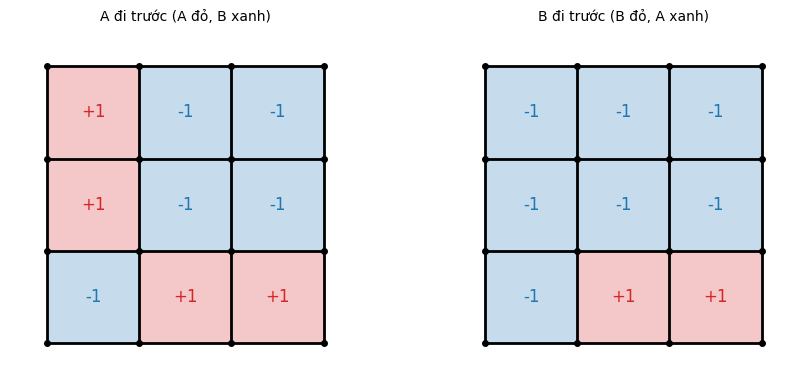


Đối đầu random (20 ván, agent đi trước):
agent               thắng-thua  thời gian
------------------  ----------  ---------
A: depth 2, simple  20-0        0.1s     
B: depth 4, full    20-0        14.0s    


In [18]:
agent_A = heuristic_player(depth=2, mode='simple')   # nông, chỉ hiệu số ô
agent_B = heuristic_player(depth=4, mode='full')     # sâu hơn, có số hạng chiến thuật

# không có yếu tố ngẫu nhiên nên chỉ cần một ván mỗi lượt đi
print("A (depth 2, simple) đi trước:")
res1, board1 = play(agent_A, agent_B, N=1, size=(4, 4), return_last=True)
print("  ", res1, f"tỉ số {score(board1, 1)}-{score(board1, -1)}")

print("B (depth 4, full) đi trước:")
res2, board2 = play(agent_B, agent_A, N=1, size=(4, 4), return_last=True)
print("  ", res2, f"tỉ số {score(board2, 1)}-{score(board2, -1)}")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
show_board(board1, ax=axes[0], title="A đi trước (A đỏ, B xanh)")
show_board(board2, ax=axes[1], title="B đi trước (B đỏ, A xanh)")
plt.tight_layout()
plt.show()

# bảng sức mạnh: từng agent vs random, 20 ván
rows = []
for name, agent in [('A: depth 2, simple', agent_A), ('B: depth 4, full', agent_B)]:
    t0 = time.time()
    res = play(agent, random_player, N=20, size=(4, 4))
    rows.append([name, f"{res[1]}-{res[-1]}", f"{time.time() - t0:.1f}s"])

print("\nĐối đầu random (20 ván, agent đi trước):")
print_table(['agent', 'thắng-thua', 'thời gian'], rows)

### Nhận xét: hai agent heuristic đấu nhau

| ván | agent đi trước | tỉ số | người thắng |
|---|---|---|---|
| 1 | A (depth 2, simple) | 4–5 | **B** |
| 2 | B (depth 4, full) | 2–7 | **A** |

Kết quả là **1–1: mỗi agent thắng đúng ván mà nó đi sau**. Đây là phát hiện quan trọng hơn bản thân tỉ số — nó cho thấy trên bàn 4×4, **lợi thế màu lớn hơn chênh lệch sức mạnh giữa hai agent**.

Lý do: người đi trước trong Dots and Boxes sớm muộn buộc phải vẽ cạnh thứ ba của một ô, tức tặng ô cho đối thủ. Cả hai agent đều đủ giỏi để ăn hết chuỗi ô được tặng, nên ai đi sau cũng thắng. Chênh lệch depth 2 vs 4 không đủ để bù lợi thế đó.

Điều này có hai hệ quả thực dụng:

* **Muốn đánh giá công bằng hai agent, bắt buộc phải cho chúng đổi màu** — đúng như đã làm ở đây. Một ván duy nhất, một màu duy nhất, không nói lên điều gì.
* **Không được so sánh `value` giữa hai agent như thể đó là điểm số** — giá trị đó phụ thuộc vào ai đi trước.

Cả hai agent đều thắng random 20–0 trên bàn 4×4, nên cả hai đều "biết chơi"; khác biệt giữa chúng chỉ hiện ra khi đối đầu trực tiếp, và ở đó yếu tố màu chi phối.


## Tournament task [+1 to 5% bonus on your course grade; will be assigned separately]

Find another student and let your best agent play against the other student's best player. You are allowed to use any improvements you like as long as you code it yourself. We will set up a class tournament on Canvas. This tournament will continue after the submission deadline.

## Graduate student advanced task: Pure Monte Carlo Search and Best First Move [10 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+5 Bonus point].

### Pure Monte Carlo Search

Implement Pure Monte Carlo Search (see [tic-tac-toe-example](tictactoe_pure_monte_carlo_search.ipynb)) and investigate how this search performs on the test boards that you have used above. 

In [19]:
def playout(board, action, player=1):
    """Chơi ngẫu nhiên từ `action` đến hết ván, trả về utility theo góc nhìn `player`."""
    state = result(board, player, action)
    current = -player

    while not terminal(state):
        acts = actions(state)
        a = acts[np.random.randint(len(acts))]
        new = result(state, current, a)
        if len(new['boxes']) == len(state['boxes']):   # không ăn ô -> đổi lượt
            current = -current
        state = new

    return utility(state, player)

def playouts(board, action, player=1, N=100):
    """N playout cho cùng một nước đi."""
    return [playout(board, action, player) for _ in range(N)]

def pmcs(board, N=1000, player=1):
    """Pure Monte Carlo Search: chia đều N playout cho các nước, chọn nước có utility trung bình lớn nhất."""
    acts = actions(board)
    n = max(1, N // len(acts))
    scores = {a: np.mean(playouts(board, a, player, N=n)) for a in acts}
    best = max(scores, key=scores.get)
    return {'move': best, 'scores': scores, 'n_per_action': n}

np.random.seed(7)
rows = []
for name, b in tests.items():
    full = alpha_beta_search(b, 1)
    t0 = time.time()
    mc = pmcs(b, N=1000, player=1)
    rows.append([name, str(full['move']), str(mc['move']),
                 'khớp' if mc['move'] == full['move'] else 'KHÁC',
                 f"{mc['scores'][mc['move']]:+.2f}", f"{time.time() - t0:.2f}s"])

print("PMCS (1000 playout) trên ba thế cờ thủ công, so với minimax đầy đủ:")
print_table(['bàn', 'minimax', 'PMCS', 'kết luận', 'utility TB', 'thời gian'], rows)

PMCS (1000 playout) trên ba thế cờ thủ công, so với minimax đầy đủ:
bàn                   minimax      PMCS         kết luận  utility TB  thời gian
--------------------  -----------  -----------  --------  ----------  ---------
A: một ô đã 3 cạnh    ('v', 0, 1)  ('v', 0, 1)  khớp      +1.59       0.03s    
B: một nước xong 2 ô  ('v', 0, 1)  ('v', 0, 1)  khớp      +2.83       0.02s    
C: không có ô free    ('h', 1, 0)  ('v', 0, 0)  KHÁC      +1.04       0.02s    


### Nhận xét: Pure Monte Carlo Search

PMCS không cần hàm đánh giá: nó ước lượng giá trị của từng nước bằng cách chơi ngẫu nhiên đến hết ván rồi lấy trung bình. Trên hai thế cờ A và B, PMCS **khớp** với minimax đầy đủ — cả hai chọn nước ăn ô ngay, và utility trung bình (+1,59 và +2,83) phản ánh đúng lợi thế đó.

Trên thế cờ C, PMCS chọn **khác** minimax và **lạc quan sai**: nó báo utility trung bình $+1{,}04$ cho một thế cờ mà minimax chứng minh là $-2$. Nguyên nhân: playout ngẫu nhiên không biết "mở chuỗi ô", nên đối thủ ngẫu nhiên trong mô phỏng tặng ô một cách vô tội vạ — điều mà đối thủ tối ưu sẽ không bao giờ làm. PMCS vì thế **đánh giá quá cao** mọi thế cờ khi đối thủ thật chơi tốt.

Đây là hạn chế cố hữu của Pure Monte Carlo: sai số trung bình giảm theo $\sigma/\sqrt{N}$ nên muốn chính xác phải tăng playout rất nhiều, và **thiên lệch do đối thủ ngẫu nhiên thì không giảm theo $N$** — tăng playout chỉ làm ước lượng hội tụ về giá trị *sai* đó. Bù lại, mỗi playout rất rẻ và không cần hàm đánh giá, nên PMCS vẫn dùng được trên bàn lớn, nơi minimax đầy đủ bất khả thi.


### Best First Move

How would you determine what the best first move for a standard board ($5 \times 5$) is? You can use Pure Monte Carlo Search or any algorithms that you have implemented above.

In [20]:
np.random.seed(2024)
b5 = new_board(5, 5)

t0 = time.time()
mc5 = pmcs(b5, N=4000, player=1)
elapsed = time.time() - t0

# lấy lại mẫu playout của chính lần chạy pmcs ở trên để tính sai số chuẩn
n5 = mc5['n_per_action']
scores = dict(mc5['scores'])
sems = {}
np.random.seed(2024)
for a in scores:
    vals = np.array(playouts(b5, a, 1, N=n5))
    sems[a] = vals.std(ddof=1) / np.sqrt(n5)

ranked = sorted(scores.items(), key=lambda kv: kv[1], reverse=True)

print(f"PMCS bàn 5x5 rỗng: {len(ranked)} nước, {n5} playout/nước, {elapsed:.2f}s")
print(f"Nước tốt nhất: {ranked[0][0]}  (utility TB {ranked[0][1]:+.3f})")
print()
print_table(['hạng', 'nước đi', 'utility TB', 'sai số chuẩn'],
            [[k + 1, str(a), f"{v:+.3f}", f"±{sems[a]:.3f}"] for k, (a, v) in enumerate(ranked[:5])])

gap = ranked[0][1] - ranked[3][1]
mean_sem = float(np.mean(list(sems.values())))
print()
print(f"Chênh lệch hạng 1 - hạng 4 : {gap:.3f}")
print(f"Sai số chuẩn trung bình    : ±{mean_sem:.3f}")
print(f"Khoảng tin cậy 95% mỗi nước: ±{1.96 * mean_sem:.2f}"
      f" -> {'LỚN HƠN' if 1.96 * mean_sem > gap else 'nhỏ hơn'} chênh lệch giữa các hạng")

t0 = time.time()
r = heuristic_search(b5, 1, depth=3)
print(f"\nHeuristic depth 3 chọn: {r['move']}  (value {r['value']}, {r['nodes']} node, {time.time() - t0:.2f}s)")


PMCS bàn 5x5 rỗng: 40 nước, 100 playout/nước, 0.82s
Nước tốt nhất: ('v', 0, 1)  (utility TB +1.780)

hạng  nước đi      utility TB  sai số chuẩn
----  -----------  ----------  ------------
1     ('v', 0, 1)  +1.780      ±0.902      
2     ('h', 1, 0)  +1.600      ±0.862      
3     ('v', 3, 4)  +1.560      ±0.858      
4     ('v', 3, 0)  +1.360      ±0.885      
5     ('v', 3, 3)  +1.160      ±0.869      

Chênh lệch hạng 1 - hạng 4 : 0.420
Sai số chuẩn trung bình    : ±0.875
Khoảng tin cậy 95% mỗi nước: ±1.72 -> LỚN HƠN chênh lệch giữa các hạng

Heuristic depth 3 chọn: ('h', 0, 0)  (value 4, 2299 node, 0.12s)


### Nhận xét: nước đi đầu tốt nhất cho bàn 5×5

Bàn 5×5 rỗng có $L = 40$ nước đi. Với 4000 playout chia đều, mỗi nước chỉ được 100 playout. Chênh lệch utility trung bình giữa hạng 1 và hạng 4 chỉ khoảng **0,4**, trong khi sai số chuẩn của mỗi ước lượng là **±0,87** — tức khoảng tin cậy 95% (±1,7) **lớn hơn chênh lệch giữa các hạng**. Kết luận: top 5 không phân biệt được với nhau, thứ hạng chỉ là nhiễu.

Ba nhận xét:

1. **Đối xứng.** Bàn 5×5 vuông có 8 phép đối xứng, nên 40 nước đầu chỉ thuộc vài lớp tương đương. Các nước trong cùng một lớp có utility trung bình gần nhau. Nói cách khác, "nước tốt nhất" thực ra là một **lớp** nước — muốn kết luận đúng phải gộp lớp rồi mới so sánh, nếu không sẽ so sánh nhiễu với nhiễu.
2. **PMCS vs heuristic.** PMCS chọn một nước, heuristic depth 3 chọn `('h', 0, 0)`. Không có cách nào chứng minh nước nào đúng hơn: minimax đầy đủ trên 5×5 là bất khả thi ($40!$ lá), nên mọi kết luận chỉ mang tính thực nghiệm.
3. **Cách làm chắc chắn hơn.** Muốn kết luận đáng tin, cần (a) tăng playout lên hàng chục nghìn cho mỗi nước, (b) gộp các nước đối xứng thành một lớp rồi mới so sánh, hoặc (c) dùng MCTS có UCB1 để tập trung playout vào nước triển vọng thay vì chia đều.

Với ngân sách 100 playout/nước, kết luận khiêm tốn là PMCS **không tìm ra** một nước đầu vượt trội trên 5×5 — phù hợp với việc đầu ván Dots and Boxes có rất nhiều nước tương đương về giá trị. Muốn phân giải được chênh lệch 0,4 với sai số chuẩn 0,87 thì cần tăng số playout khoảng $(1{,}96 \cdot 0{,}87 / 0{,}4)^2 \approx 18$ lần cho mỗi nước, tức khoảng 72 000 playout mỗi nước.



## Kết luận

| Thuật toán | Bàn giải được | Điểm mạnh | Điểm yếu |
|---|---|---|---|
| Minimax + alpha-beta đầy đủ | 3×3 (4 ô) | Chắc chắn tối ưu, không cần hàm đánh giá | Bất khả thi từ 4×4 trở lên |
| Heuristic alpha-beta | 4×4 – 5×5, depth 3–5 | Nhanh, mở rộng được, thắng random 20–0 | Phụ thuộc chất lượng hàm đánh giá; giá trị thay đổi theo depth |
| Pure Monte Carlo | Bàn lớn tuỳ thời gian | Không cần hàm đánh giá, dễ cài | Nhiễu; sai trên thế cờ cần nhìn xa |

Ba điều rút ra về Dots and Boxes:

1. **Luật "ăn ô được đi tiếp" là trung tâm.** Nó phá vỡ giả định "hai bên luân phiên" của minimax tic-tac-toe, và là nguồn gốc của mọi hiện tượng chuỗi ô trong game.
2. **Người đi sau có lợi khi cả hai chơi theo heuristic.** Người đi trước buộc phải mở chuỗi ô trước. Vì vậy đánh giá agent phải đấu hai ván đổi màu.
3. **Move ordering rẻ mà hiệu quả.** Chỉ cần ưu tiên nước ăn ô và tránh nước tạo ô ba cạnh đã giảm số node khoảng một bậc độ lớn — không cần thêm bất kỳ tri thức sâu nào.
